## **Nama : Zalsabilah Nurdin**
## **Nim : H061241001**
## **Tugas recipes**

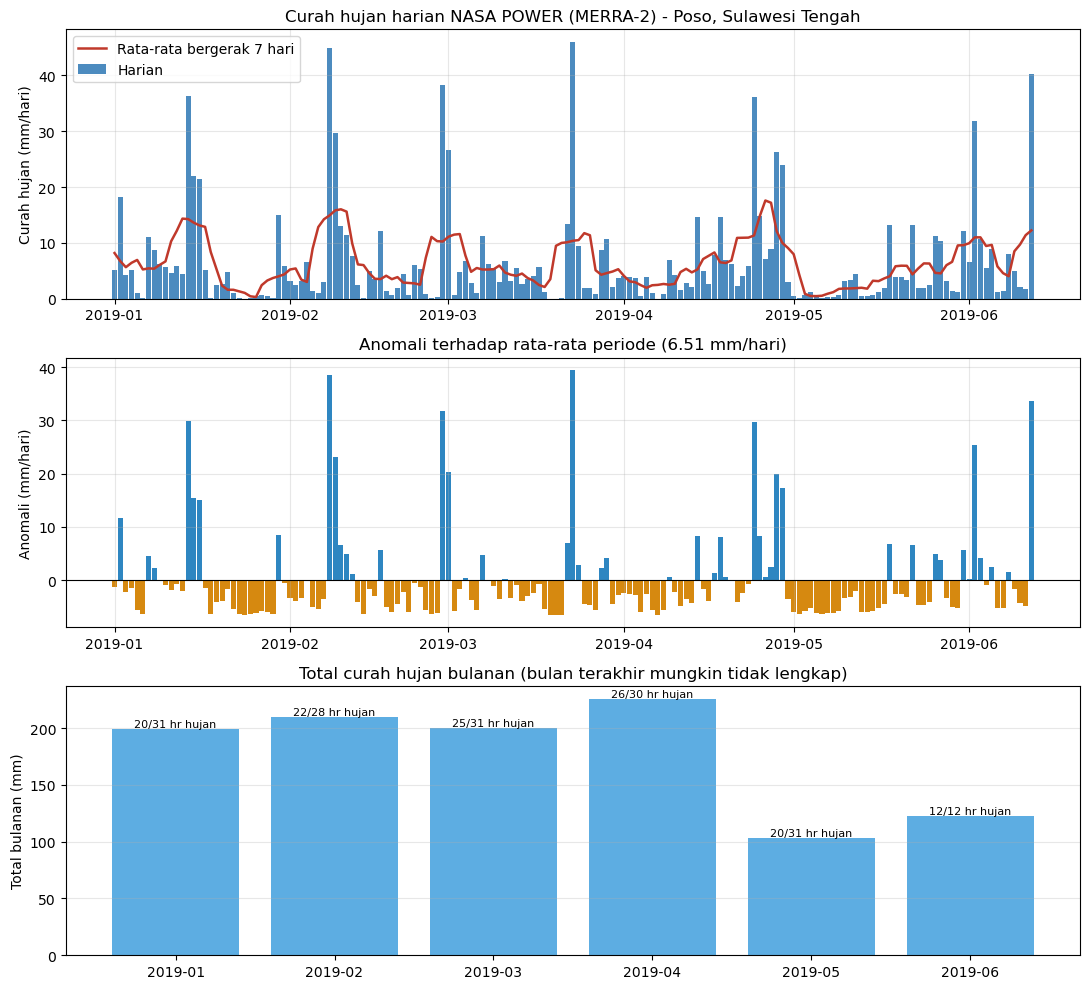

,item,nilai
0,lokasi,"Poso, Sulawesi Tengah"
1,lintang,-1.3734
2,bujur,120.7703
3,elevasi_grid_MERRA2_m,913.29
4,tanggal_awal,2019-01-01
5,tanggal_akhir,2019-06-12
6,jumlah_hari_seharusnya,163
7,nilai_-999_diganti_NaN,0
8,nilai_negatif_diganti_NaN,0
9,tanggal_hilang,0


,jumlah_hari,total_mm,rata_harian_mm,maks_harian_mm,hari_hujan,hari_hujan_persen
bulan,,,,,,
2019-01,31,199.24,6.43,36.37,20.0,64.5
2019-02,28,210.11,7.50,44.92,22.0,78.6
2019-03,31,200.06,6.45,45.97,25.0,80.6
2019-04,30,225.75,7.52,36.16,26.0,86.7
2019-05,31,103.02,3.32,13.23,20.0,64.5
2019-06,12,122.95,10.25,40.19,12.0,100.0


Tersimpan di: C:\Users\Thinkpad\Downloads\outputs_hujan


In [6]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
try: from IPython.display import display  
except ImportError: display = print                       


FILE_INPUT = Path.home() / "Downloads" / "POWER_Point_Daily_20190101_20190612_001d37S_120d77E_LST.csv"
FOLDER_OUTPUT = Path.home() / "Downloads" / "outputs_hujan"
NAMA_LOKASI = "Poso, Sulawesi Tengah"
AMBANG_HARI_HUJAN = 1.0     
JENDELA_RATA_BERGERAK = 7   
NILAI_KOSONG = -999
 
# Tampilkan tabel 
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", None)
 
FOLDER_OUTPUT.mkdir(parents=True, exist_ok=True)
 

with open(FILE_INPUT, "r", encoding="utf-8") as f:
    baris = f.read().splitlines()
 
idx_akhir_header = 0
for i in range(len(baris)):
    if baris[i].strip() == "-END HEADER-":
        idx_akhir_header = i
        break
 
header_teks = baris[: idx_akhir_header + 1]
lat = np.nan
lon = np.nan
elevasi_m = np.nan
for teks in header_teks:
    if teks.startswith("Location:"):
        potongan = teks.split()
        lat = float(potongan[2])
        lon = float(potongan[4])
    if teks.startswith("elevation"):
        elevasi_m = float(teks.split("=")[1].replace("meters", "").strip())
 
df = pd.read_csv(FILE_INPUT, skiprows=idx_akhir_header + 1)
 

# BUAT KOLOM TANGGAL DARI YEAR + DOY

df["tanggal"] = pd.to_datetime(
    df["YEAR"].astype(str) + df["DOY"].astype(str).str.zfill(3),
    format="%Y%j",
)
df = df.rename(columns={"PRECTOTCORR": "hujan_mm"})
 

# QC: NILAI KOSONG, NEGATIF, DAN GAP WAKTU  (R-QC-001, R-QC-002)

jumlah_kosong = int((df["hujan_mm"] == NILAI_KOSONG).sum())
df["hujan_mm"] = df["hujan_mm"].replace(NILAI_KOSONG, np.nan)
 
jumlah_negatif = int((df["hujan_mm"] < 0).sum())
df.loc[df["hujan_mm"] < 0, "hujan_mm"] = np.nan
 
df = df.sort_values("tanggal").reset_index(drop=True)
 
rentang_penuh = pd.date_range(df["tanggal"].min(), df["tanggal"].max(), freq="D")
tanggal_hilang = rentang_penuh.difference(df["tanggal"])
jumlah_duplikat = int(df["tanggal"].duplicated().sum())
 
# Reindex 
df = df.set_index("tanggal").reindex(rentang_penuh)
df.index.name = "tanggal"
df["YEAR"] = df.index.year
df["DOY"] = df.index.dayofyear
df["bulan"] = df.index.to_period("M").astype(str)
 

#  TURUNAN: KATEGORI HUJAN, ANOMALI, RATA-RATA BERGERAK, KUMULATIF
#  Kategori mengikuti klasifikasi intensitas harian umum (BMKG):
#  <0.5 tidak hujan | 0.5-20 ringan-sedang | 20-50 lebat | 50-100 sangat lebat | >100 ekstrem
#  (periksa ulang ambang sesuai standar yang Anda rujuk)

batas = [-np.inf, 0.5, 20, 50, 100, np.inf]
label = ["tidak hujan", "ringan-sedang", "lebat", "sangat lebat", "ekstrem"]
df["kategori"] = pd.cut(df["hujan_mm"], bins=batas, labels=label, right=False)
 
rata_periode = df["hujan_mm"].mean()
df["anomali_mm"] = df["hujan_mm"] - rata_periode  # terhadap rata-rata periode (R-CAL-002)
df["rata_bergerak"] = df["hujan_mm"].rolling(
    JENDELA_RATA_BERGERAK, center=True, min_periods=3
).mean()
df["kumulatif_mm"] = df["hujan_mm"].cumsum()
 

#  RINGKASAN BULANAN  

df["hari_hujan"] = (df["hujan_mm"] >= AMBANG_HARI_HUJAN).astype(int)
df.loc[df["hujan_mm"].isna(), "hari_hujan"] = np.nan
 
bulanan = df.groupby("bulan").agg(
    jumlah_hari=("hujan_mm", "size"),
    total_mm=("hujan_mm", "sum"),
    rata_harian_mm=("hujan_mm", "mean"),
    maks_harian_mm=("hujan_mm", "max"),
    hari_hujan=("hari_hujan", "sum"),
).round(2)
bulanan["hari_hujan_persen"] = (
    bulanan["hari_hujan"] / bulanan["jumlah_hari"] * 100
).round(1)
 

#  KUALITAS & STATISTIK  
tgl_maks = df["hujan_mm"].idxmax()
ringkasan = pd.DataFrame(
    {
        "item": [
            "lokasi", "lintang", "bujur", "elevasi_grid_MERRA2_m",
            "tanggal_awal", "tanggal_akhir", "jumlah_hari_seharusnya",
            "nilai_-999_diganti_NaN", "nilai_negatif_diganti_NaN",
            "tanggal_hilang", "duplikat", "hari_valid",
            "total_mm", "rata_harian_mm", "median_mm", "std_mm",
            "maks_harian_mm", "tanggal_maks", "persen_hari_hujan",
        ],
        "nilai": [
            NAMA_LOKASI, lat, lon, elevasi_m,
            df.index.min().date(), df.index.max().date(), len(df),
            jumlah_kosong, jumlah_negatif,
            len(tanggal_hilang), jumlah_duplikat, int(df["hujan_mm"].notna().sum()),
            round(df["hujan_mm"].sum(), 2), round(rata_periode, 2),
            round(df["hujan_mm"].median(), 2), round(df["hujan_mm"].std(), 2),
            df["hujan_mm"].max(), tgl_maks.date(),
            round(df["hari_hujan"].mean() * 100, 1),],})
 
# SIMPAN CSV
kolom_simpan = [
    "YEAR", "DOY", "hujan_mm", "kategori", "anomali_mm",
    "rata_bergerak", "kumulatif_mm",
]
df[kolom_simpan].round(3).to_csv(FOLDER_OUTPUT / "hujan_harian_bersih.csv")
bulanan.to_csv(FOLDER_OUTPUT / "hujan_ringkasan_bulanan.csv")
ringkasan.to_csv(FOLDER_OUTPUT / "hujan_ringkasan_kualitas.csv", index=False)
 

#  VISUALISASI  
fig, sumbu = plt.subplots(3, 1, figsize=(11, 10), sharex=False)
 
# (a) hujan harian + rata-rata bergerak
sumbu[0].bar(df.index, df["hujan_mm"], color="#4c8bbf", width=0.9, label="Harian")
sumbu[0].plot(
    df.index, df["rata_bergerak"], color="#c0392b", lw=1.8,
    label=f"Rata-rata bergerak {JENDELA_RATA_BERGERAK} hari",
)
sumbu[0].set_ylabel("Curah hujan (mm/hari)")
sumbu[0].set_title(f"Curah hujan harian NASA POWER (MERRA-2) - {NAMA_LOKASI}")
sumbu[0].legend()
sumbu[0].grid(alpha=0.3)
 
# (b) anomali terhadap rata-rata periode
warna = np.where(df["anomali_mm"] >= 0, "#2e86c1", "#d68910")
sumbu[1].bar(df.index, df["anomali_mm"], color=warna, width=0.9)
sumbu[1].axhline(0, color="k", lw=0.8)
sumbu[1].set_ylabel("Anomali (mm/hari)")
sumbu[1].set_title(f"Anomali terhadap rata-rata periode ({rata_periode:.2f} mm/hari)")
sumbu[1].grid(alpha=0.3)
 
# (c) total bulanan + jumlah hari hujan
posisi = np.arange(len(bulanan))
sumbu[2].bar(posisi, bulanan["total_mm"], color="#5dade2")
sumbu[2].set_xticks(posisi)
sumbu[2].set_xticklabels(bulanan.index, rotation=0)
sumbu[2].set_ylabel("Total bulanan (mm)")
sumbu[2].set_title("Total curah hujan bulanan (bulan terakhir mungkin tidak lengkap)")
sumbu[2].grid(alpha=0.3, axis="y")
for i in range(len(bulanan)):
    sumbu[2].text(
        posisi[i], bulanan["total_mm"].iloc[i],
        f'{bulanan["hari_hujan"].iloc[i]:.0f}/{bulanan["jumlah_hari"].iloc[i]} hr hujan',
        ha="center", va="bottom", fontsize=8,
    )
 
fig.tight_layout()
fig.savefig(FOLDER_OUTPUT / "hujan_harian.png", dpi=150)
plt.show()
 

#  TAMPILKAN HASIL
display(ringkasan)
display(bulanan)
print("Tersimpan di:", FOLDER_OUTPUT.resolve())